# TCC ML - Extinção
#### João Avila Harduin - 00332195
#### Kauã Cordeiro Cavalheiro - 00331660
#### Luan Bonasorte Capella - 00332061
-----

## Professora orientadora
#### Edith Ranzini

## Notebook 2 de 3 — Modelagem

Treinamento e avaliação de Random Forest, SVM e XGBoost sobre o dataset construído no notebook 01: efeito do vazamento de `redlistCategory`, escalonamento, importância das features, SMOTE × SMOTENC e ajuste de hiperparâmetros. A tabela consolidada (Seção 10) é salva em `resultados/resultados_modelagem.csv` e usada pelo notebook 03.

| Notebook | Conteúdo |
|---|---|
| `01_construcao_dataset.ipynb` | Seções 1–5: aquisição, análise exploratória, construção do dataset e pré-processamento |
| `02_modelagem.ipynb` | Seções 6–10: Random Forest, SVM e XGBoost, SMOTE × SMOTENC, ajuste de hiperparâmetros e tabela consolidada |
| `03_fronteira_e_limpeza.ipynb` | Seções 11–13: diagnóstico de fronteira, limpeza (ENN e Passo 1) e Teste 4 |

### Sumário deste notebook

Setup e dados
6. Modelos Base (Random Forest e SVM)
7. Ajuste de Hiperparâmetros (SMOTE e dados originais)
8. SMOTENC
9. XGBoost (SMOTENC)
10. Tabela Consolidada de Resultados (10.1: exportação)

> No Colab, use o painel **Índice** (ícone ☰ à esquerda) para navegar entre as seções. O código reutilizado fica em `src/tcc_extincao/`; as correções metodológicas estão descritas no `README.md`.

## Setup

Prepara o ambiente (no Colab, clona o repositório e instala o `matplotlib-venn`) e importa o pacote `tcc_extincao`.

> **Tempo de execução:** os `GridSearchCV` levam horas no Colab gratuito. Por padrão, os melhores hiperparâmetros salvos em `resultados/buscas/` são reaproveitados e só o modelo final é treinado (o resultado é o mesmo). Para refazer as buscas, descomente `config.REFAZER_BUSCAS = True` na célula de imports.

In [1]:
# No Colab, clona o repositório (os dados são baixados do Google Drive pelo
# próprio notebook); localmente, usa a pasta do repositório
import sys
from pathlib import Path

REPO_URL = 'https://github.com/kcac1108/tcc-ml-extincao.git'

if 'google.colab' in sys.modules:
    RAIZ = Path('/content/tcc-ml-extincao')
    if not RAIZ.exists():
        !git clone -q {REPO_URL} {RAIZ}
    %pip install -q matplotlib-venn
else:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'tcc_extincao').exists())

sys.path.insert(0, str(RAIZ / 'src'))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE, SMOTENC
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

from tcc_extincao import config, dados, modelos, avaliacao, graficos, preprocessamento as prep
from tcc_extincao.config import RANDOM_STATE, TEST_SIZE

# Para refazer os GridSearchCV (horas no Colab gratuito), descomente a linha abaixo
# config.REFAZER_BUSCAS = True

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 80)

### Dados

Reconstruímos o dataset e o split treino/teste exatamente como no notebook 01, e aplicamos o SMOTE no treino (Seção 5.3).

In [3]:
# Mesmo dataset e mesmo split treino/teste do notebook 01 (RANDOM_STATE fixo)
dataset = dados.construir_dataset()
df, colunas_systems = prep.codificar(dataset)
X, y = prep.separar_X_y(df)
X_treino, X_teste, y_treino, y_teste = prep.dividir_treino_teste(X, y)

# Versões sem redlistCategory (data leakage), usadas na maior parte dos experimentos
X_treino_base, X_teste_base = prep.sem_redlist(X_treino), prep.sem_redlist(X_teste)
colunas_categoricas, indices_categoricos = prep.colunas_categoricas(X_treino_base, colunas_systems)

print(f'Treino: {X_treino.shape}  |  Teste: {X_teste.shape}')

X_treino_balanceado, y_treino_balanceado = SMOTE(random_state=RANDOM_STATE).fit_resample(X_treino, y_treino)
resultados_experimentos = []

assessments.csv já existe, download pulado.
Rodentia_gbif.csv já existe, download pulado.
taxonomy.csv já existe, download pulado.


Dataset: 721 espécies x 30 colunas
Treino: (576, 344)  |  Teste: (145, 344)


## 6. Modelos Base (Random Forest e SVM)
Começaremos utilizando a configuração padrão dos modelos Random Forest e SVM, sem ajustes de hiperparâmetros, no dataset montado e balanceado.

### 6.1 Treinamento com configuração padrão (com `redlistCategory`)

In [4]:
rf_model_redlist = RandomForestClassifier(random_state=RANDOM_STATE)
_ = modelos.treinar_e_avaliar(rf_model_redlist, X_treino_balanceado, y_treino_balanceado,
                              X_teste, y_teste, 'Random Forest')

### Random Forest ###



Tempo de treinamento: 0.0948 segundos

Relatório de Classificação Random Forest:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       133
           1       1.00      1.00      1.00        12

    accuracy                           1.00       145
   macro avg       1.00      1.00      1.00       145
weighted avg       1.00      1.00      1.00       145

Matriz de Confusão Random Forest:
 [[133   0]
 [  0  12]]
Acurácia Random Forest: 1.0000


In [5]:
svm_model_redlist = SVC(random_state=RANDOM_STATE)
print(f"Kernel utilizado: {svm_model_redlist.kernel}")
_ = modelos.treinar_e_avaliar(svm_model_redlist, X_treino_balanceado, y_treino_balanceado,
                              X_teste, y_teste, 'SVM')

Kernel utilizado: rbf
### SVM ###

Tempo de treinamento: 0.0500 segundos

Relatório de Classificação SVM:
              precision    recall  f1-score   support

           0       0.97      0.86      0.91       133
           1       0.31      0.67      0.42        12

    accuracy                           0.85       145
   macro avg       0.64      0.77      0.67       145
weighted avg       0.91      0.85      0.87       145

Matriz de Confusão SVM:
 [[115  18]
 [  4   8]]
Acurácia SVM: 0.8483


### 6.2 Remoção de `redlistCategory` (data leakage)

Removemos a feature `redlistCategory` para evitar *data leakage*, pois `label`, nossa variável alvo, é derivada dela.

> **Correção:** o SMOTE é refeito sem `redlistCategory`. Antes, as amostras sintéticas usadas daqui em diante eram geradas com a coluna vazada participando do cálculo dos vizinhos.

In [6]:
# O SMOTE é refeito sem redlistCategory: se a coluna participasse do cálculo
# dos vizinhos, as amostras sintéticas seriam geradas com ajuda da feature vazada
X_treino_sem_redlist, y_treino_sem_redlist = SMOTE(random_state=RANDOM_STATE).fit_resample(X_treino_base, y_treino)
# O SMOTE só acrescenta amostras da classe minoritária ao final, então os rótulos
# são os mesmos de y_treino_balanceado, usado nas células seguintes
assert np.array_equal(y_treino_sem_redlist.values, y_treino_balanceado.values)

rf_model = RandomForestClassifier(random_state=RANDOM_STATE)
y_pred_rf, tempo_treino_rf = modelos.treinar_e_avaliar(rf_model, X_treino_sem_redlist, y_treino_balanceado,
                                                       X_teste_base, y_teste, 'Random Forest')

### Random Forest ###


Tempo de treinamento: 0.1046 segundos

Relatório de Classificação Random Forest:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       133
           1       0.47      0.58      0.52        12

    accuracy                           0.91       145
   macro avg       0.71      0.76      0.73       145
weighted avg       0.92      0.91      0.91       145

Matriz de Confusão Random Forest:
 [[125   8]
 [  5   7]]
Acurácia Random Forest: 0.9103


In [7]:
svm_model = SVC(random_state=RANDOM_STATE)
_ = modelos.treinar_e_avaliar(svm_model, X_treino_sem_redlist, y_treino_balanceado,
                              X_teste_base, y_teste, 'SVM')

### SVM ###

Tempo de treinamento: 0.0507 segundos

Relatório de Classificação SVM:
              precision    recall  f1-score   support

           0       0.97      0.86      0.91       133
           1       0.31      0.67      0.42        12

    accuracy                           0.85       145
   macro avg       0.64      0.77      0.67       145
weighted avg       0.91      0.85      0.87       145

Matriz de Confusão SVM:
 [[115  18]
 [  4   8]]
Acurácia SVM: 0.8483


### 6.3 Importância das features — Random Forest

Para entender quais características mais influenciam a decisão do modelo Random Forest, podemos analisar a importância das features. Isso nos ajuda a identificar os atributos mais relevantes para prever se uma espécie é 'Ameaçada' ou 'Não Ameaçada'.

Top 10 Features por Importância no Random Forest:
                       feature  importance
26      populationTrend_Stable    0.104101
16      coord_uncertainty_mean    0.101308
24  populationTrend_Decreasing    0.089644
0                yearPublished    0.079735
27     populationTrend_Unknown    0.058970
17                   lat_range    0.031674
18                   lon_range    0.030391
7                      lon_std    0.029670
5                      lat_std    0.029060
4                     lat_mean    0.026816


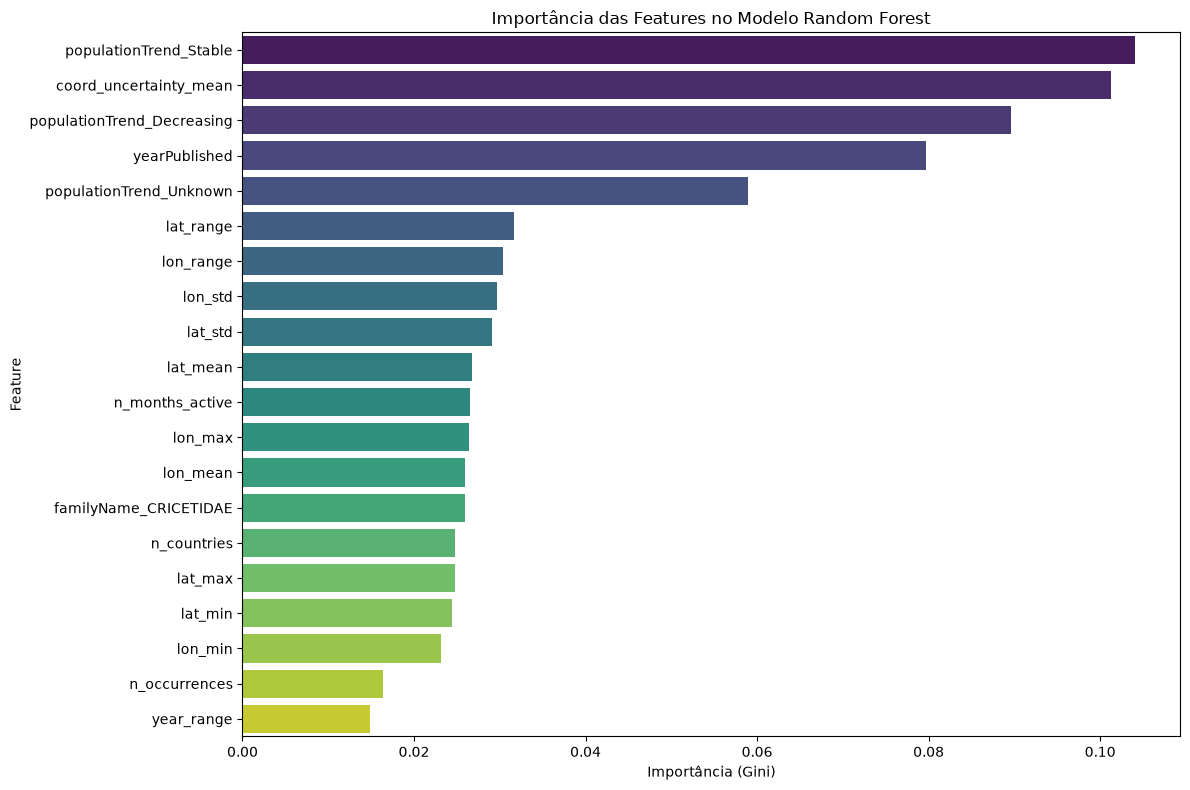

In [8]:
feature_importances = avaliacao.importancia_gini(rf_model, X_treino_sem_redlist.columns)

print("Top 10 Features por Importância no Random Forest:")
print(feature_importances.head(10))

graficos.plot_importancias(feature_importances, 'Importância das Features no Modelo Random Forest', 'Importância (Gini)')

### 6.4 Importância das features — SVM

Diferente do Random Forest, o SVM (com o kernel padrão) não expõe um atributo `feature_importances_` nem `coef_` diretamente interpretável — o kernel RBF projeta os dados em um espaço de dimensão maior, o que torna a leitura direta dos coeficientes inviável (isso só é direto para kernel `linear`).

Por isso, usamos a **Permutation Importance**: embaralhamos os valores de cada feature (uma por vez) no conjunto de teste e medimos o quanto a performance do modelo cai. Quanto maior a queda, mais importante é a feature para o SVM.

Referência: [Determining Feature Importance in SVM Classifiers with Scikit-Learn](https://www.geeksforgeeks.org/machine-learning/determining-feature-importance-in-svm-classifiers-with-scikit-learn/)

Top 10 Features por Importância no SVM (Permutation Importance):
                    feature  importance  importance_std
16   coord_uncertainty_mean        0.08        0.024519
0             yearPublished        0.00        0.000000
236       genusName_Nesokia        0.00        0.000000
234     genusName_Neotamias        0.00        0.000000
233      genusName_Neofiber        0.00        0.000000
232        genusName_Neodon        0.00        0.000000
231      genusName_Nectomys        0.00        0.000000
230      genusName_Necromys        0.00        0.000000
229      genusName_Neacomys        0.00        0.000000
228   genusName_Napaeozapus        0.00        0.000000


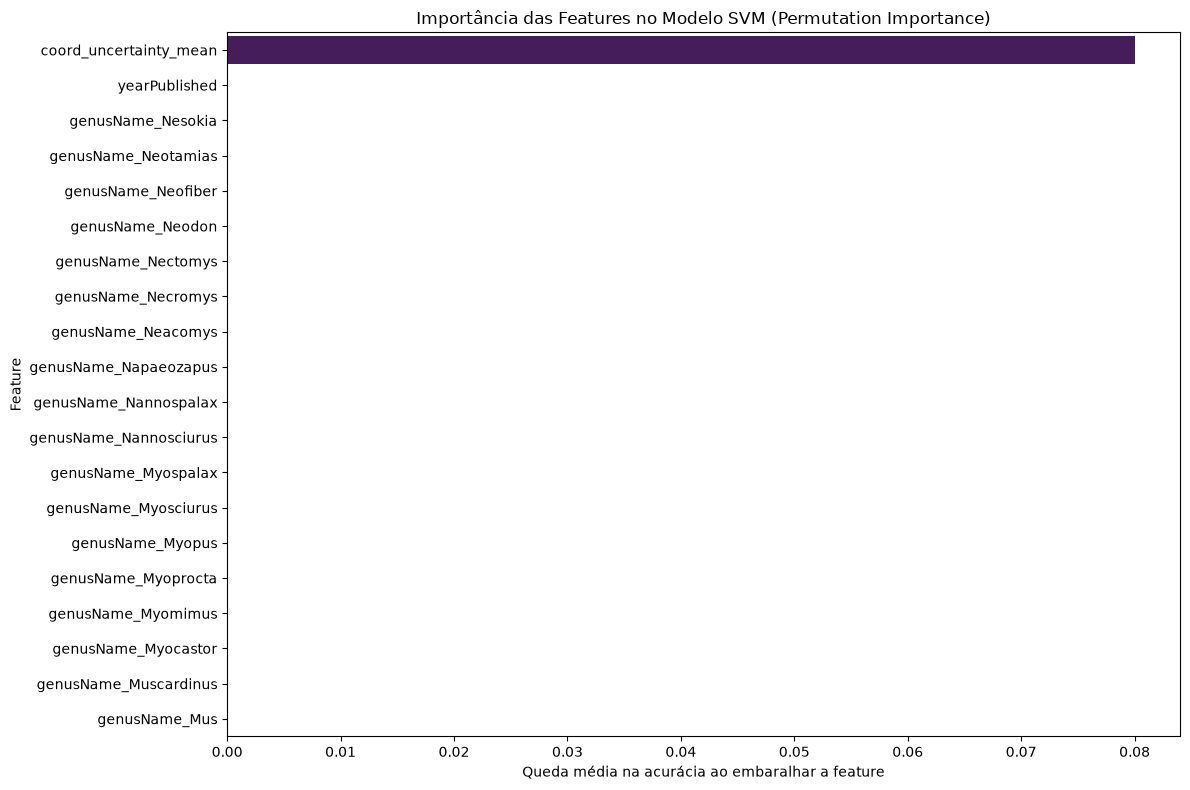

In [9]:
svm_importancias_sem_escala = avaliacao.importancia_permutacao(svm_model, X_teste_base, y_teste)

print("Top 10 Features por Importância no SVM (Permutation Importance):")
print(svm_importancias_sem_escala.head(10))

graficos.plot_importancias(svm_importancias_sem_escala,
                           'Importância das Features no Modelo SVM (Permutation Importance)',
                           'Queda média na acurácia ao embaralhar a feature')

### 6.5 SVM com StandardScaler

SVM (kernel RBF) é sensível à escala das features: sem escalonar, features com
range maior (ex: n_occurrences) dominam o cálculo de distância do kernel e "abafam" as demais. Por isso, escalonamos com StandardScaler antes de treinar.

In [10]:
X_treino_scaled, X_teste_scaled = prep.escalonar(X_treino_sem_redlist, X_teste_base)

svm_model_scaled = SVC(random_state=RANDOM_STATE)
print(f"Kernel utilizado: {svm_model_scaled.kernel}")
y_pred_svm, tempo_treino_svm = modelos.treinar_e_avaliar(svm_model_scaled, X_treino_scaled, y_treino_balanceado,
                                                         X_teste_scaled, y_teste, 'SVM')

Kernel utilizado: rbf
### SVM ###



Tempo de treinamento: 0.0229 segundos

Relatório de Classificação SVM:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88       133
           1       0.12      0.25      0.16        12

    accuracy                           0.79       145
   macro avg       0.52      0.54      0.52       145
weighted avg       0.86      0.79      0.82       145

Matriz de Confusão SVM:
 [[111  22]
 [  9   3]]
Acurácia SVM: 0.7862


#### Importância das features do SVM escalonado — versão original

> Esta versão calcula a importância no conjunto de **teste**. Veja a versão corrigida logo abaixo.

Top 10 Features por Importância no SVM (Permutation Importance):
                        feature  importance  importance_std
27      populationTrend_Unknown    0.016552        0.010322
201           genusName_Marmota    0.016552        0.003379
50        familyName_CRICETIDAE    0.015172        0.008043
26       populationTrend_Stable    0.014483        0.016159
24   populationTrend_Decreasing    0.013103        0.014614
294        genusName_Rhipidomys    0.011724        0.003160
334       genusName_Urocitellus    0.006897        0.000000
106           genusName_Calomys    0.006897        0.000000
124           genusName_Cynomys    0.006207        0.002069
266        genusName_Petaurista    0.006207        0.002069


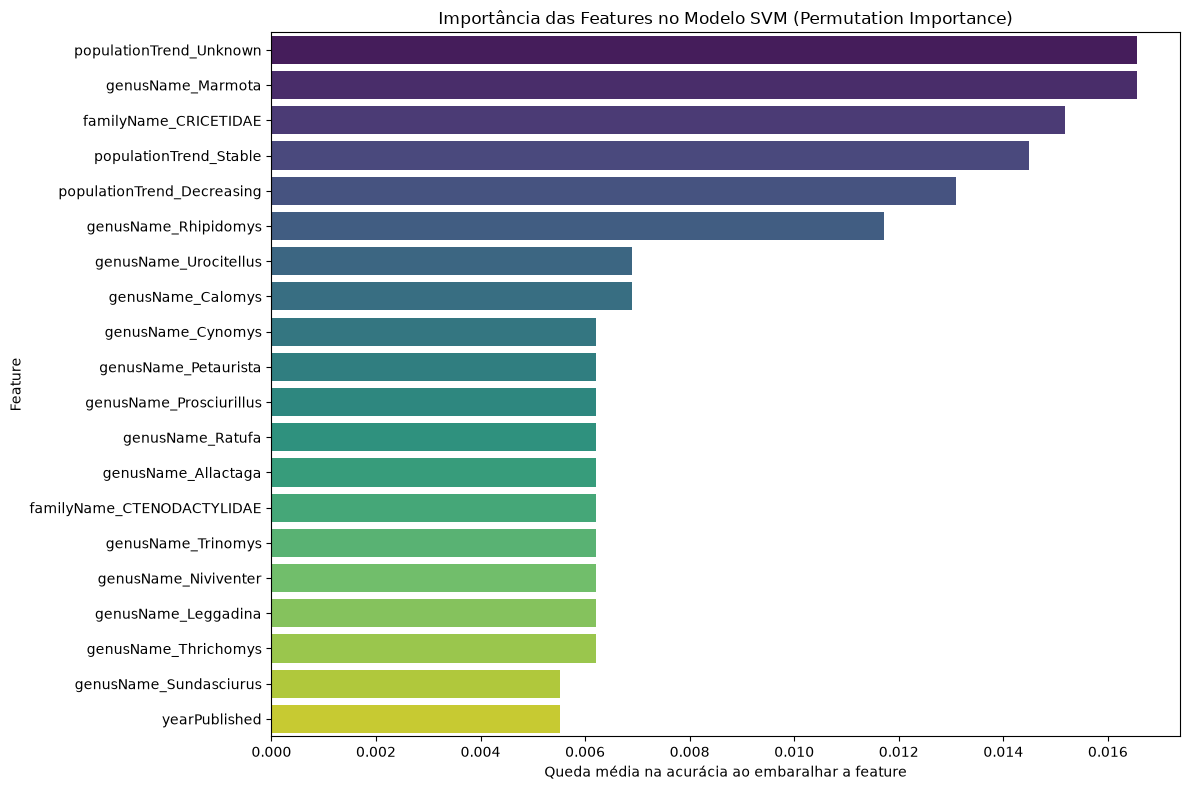

In [11]:
svm_feature_importances = avaliacao.importancia_permutacao(svm_model_scaled, X_teste_scaled, y_teste)

print("Top 10 Features por Importância no SVM (Permutation Importance):")
print(svm_feature_importances.head(10))

graficos.plot_importancias(svm_feature_importances,
                           'Importância das Features no Modelo SVM (Permutation Importance)',
                           'Queda média na acurácia ao embaralhar a feature')

#### Importância das features do SVM escalonado — versão corrigida (Correção 3)

**Problema na versão original (célula acima):** o `permutation_importance` foi calculado usando `X_teste_scaled` / `y_teste` — ou seja, o conjunto de teste foi usado para **decidir** quais features são importantes. Isso "vaza" informação do teste para uma decisão de modelagem, antes da avaliação final.

**Correção:** separamos uma fatia de validação (20%) **dentro do treino** (nunca usada no `.fit()` do modelo abaixo), calculamos a importância das features nela, e deixamos o teste intocado até a avaliação final do trade-off.

As variáveis abaixo têm sufixo `_corrigido` para não sobrescrever as originais (`svm_feature_importances`, etc.) — assim dá pra comparar os dois rankings.

In [12]:
# --- Correção: separar um conjunto de VALIDAÇÃO (retirado do treino) para
# calcular a importância das features do SVM, em vez de usar o conjunto de teste.
X_sub_treino_svm, X_val_svm, y_sub_treino_svm, y_val_svm = train_test_split(
    X_treino_scaled, y_treino_balanceado,
    test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y_treino_balanceado
)

svm_model_val = SVC(random_state=RANDOM_STATE)
svm_model_val.fit(X_sub_treino_svm, y_sub_treino_svm)

print(f"Acurácia do SVM na validação: {accuracy_score(y_val_svm, svm_model_val.predict(X_val_svm)):.4f}")

Acurácia do SVM na validação: 0.9528


Top 10 Features por Importância no SVM — CORRIGIDO (Permutation Importance na validação):
                    feature  importance  importance_std
313  genusName_Spermophilus    0.020283        0.004245
238    genusName_Niviventer    0.016509        0.004349
104  genusName_Callosciurus    0.013679        0.004925
113  genusName_Chiropodomys    0.008491        0.003530
92       genusName_Arvicola    0.008491        0.003530
245       genusName_Oecomys    0.008491        0.002830
265    genusName_Peromyscus    0.008019        0.002162
260     genusName_Parotomys    0.007547        0.002311
100       genusName_Belomys    0.007075        0.002358
106       genusName_Calomys    0.007075        0.002358


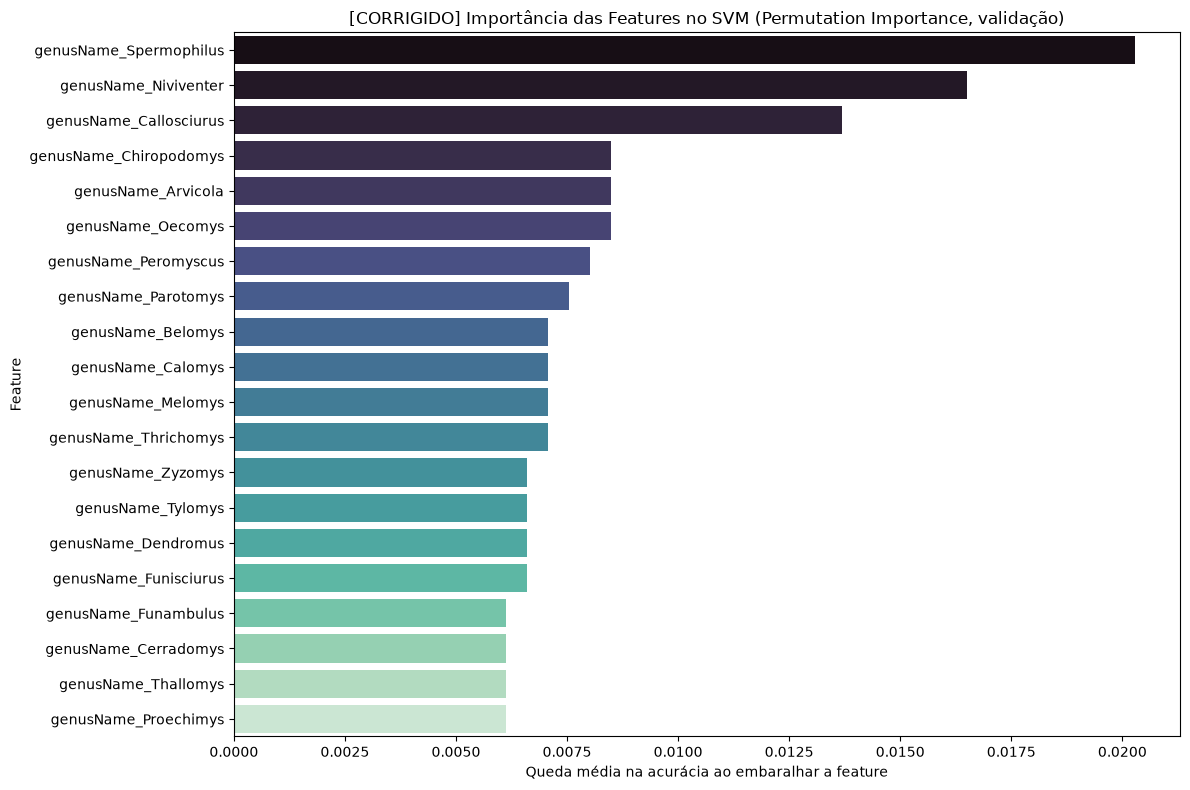

In [13]:
# Usa o conjunto de VALIDAÇÃO (não o teste) para não vazar informação do
# teste na escolha de quais features manter.
svm_feature_importances_corrigido = avaliacao.importancia_permutacao(svm_model_val, X_val_svm, y_val_svm)

print("Top 10 Features por Importância no SVM — CORRIGIDO (Permutation Importance na validação):")
print(svm_feature_importances_corrigido.head(10))

graficos.plot_importancias(svm_feature_importances_corrigido,
                           '[CORRIGIDO] Importância das Features no SVM (Permutation Importance, validação)',
                           'Queda média na acurácia ao embaralhar a feature', palette='mako')

### 6.6 Random Forest com StandardScaler

Retreinamos o Random Forest com StandardScaler (os mesmos dados escalonados da Seção 6.5), para padronizar a pipeline de execução entre os modelos.

In [14]:
rf_model_scaled = RandomForestClassifier(random_state=RANDOM_STATE)
y_pred_rf_scaled, tempo_treino_rf_scaled = modelos.treinar_e_avaliar(
    rf_model_scaled, X_treino_scaled, y_treino_balanceado, X_teste_scaled, y_teste,
    'Random Forest (com StandardScaler)')

### Random Forest (com StandardScaler) ###



Tempo de treinamento: 0.1085 segundos

Relatório de Classificação Random Forest (com StandardScaler):
              precision    recall  f1-score   support

           0       0.96      0.94      0.95       133
           1       0.47      0.58      0.52        12

    accuracy                           0.91       145
   macro avg       0.71      0.76      0.73       145
weighted avg       0.92      0.91      0.91       145

Matriz de Confusão Random Forest (com StandardScaler):
 [[125   8]
 [  5   7]]
Acurácia Random Forest (com StandardScaler): 0.9103


Top 10 Features por Importância no Random Forest (com StandardScaler):
                       feature  importance
26      populationTrend_Stable    0.104101
16      coord_uncertainty_mean    0.101308
24  populationTrend_Decreasing    0.089644
0                yearPublished    0.079735
27     populationTrend_Unknown    0.058970
17                   lat_range    0.031674
18                   lon_range    0.030391
7                      lon_std    0.029670
5                      lat_std    0.029060
4                     lat_mean    0.026816


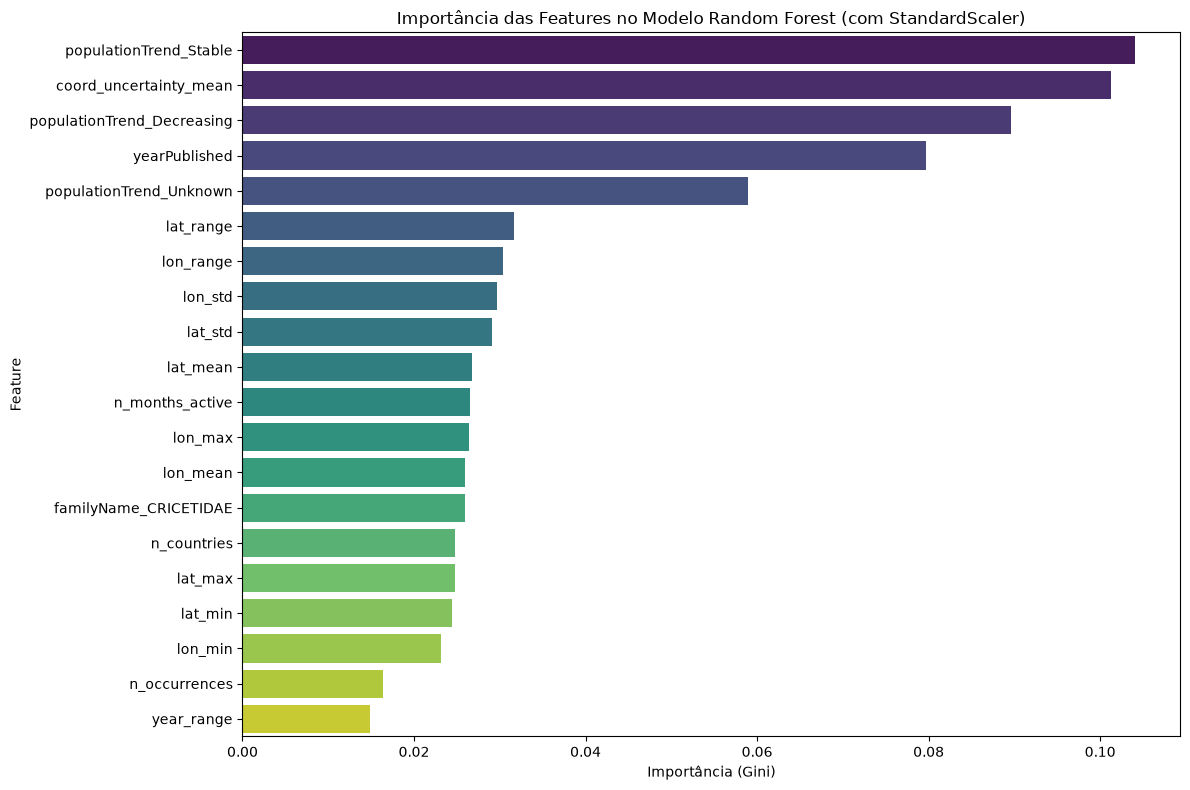

In [15]:
rf_scaled_feature_importances = avaliacao.importancia_gini(rf_model_scaled, X_treino_scaled.columns)

print("Top 10 Features por Importância no Random Forest (com StandardScaler):")
print(rf_scaled_feature_importances.head(10))

graficos.plot_importancias(rf_scaled_feature_importances,
                           'Importância das Features no Modelo Random Forest (com StandardScaler)',
                           'Importância (Gini)')

### 6.7 Trade-off: quantidade de features × desempenho

Treinamos RF e SVM usando apenas as N features mais importantes de cada ranking, medindo tempo de treinamento e acurácia.

#### Versão original

In [16]:
# Todas as features, depois 30, 25, 20, 15, 10, 5
total_features = X_treino_scaled.shape[1]
contagens = sorted(set([total_features] + list(range(30, 0, -5))), reverse=True)

rf_df = modelos.avaliar_tradeoff(rf_scaled_feature_importances['feature'].tolist(),
                                 X_treino_scaled, y_treino_balanceado, X_teste_scaled, y_teste,
                                 lambda seed: RandomForestClassifier(random_state=seed), contagens)
svm_df = modelos.avaliar_tradeoff(svm_feature_importances['feature'].tolist(),
                                  X_treino_scaled, y_treino_balanceado, X_teste_scaled, y_teste,
                                  lambda seed: SVC(random_state=seed), contagens)

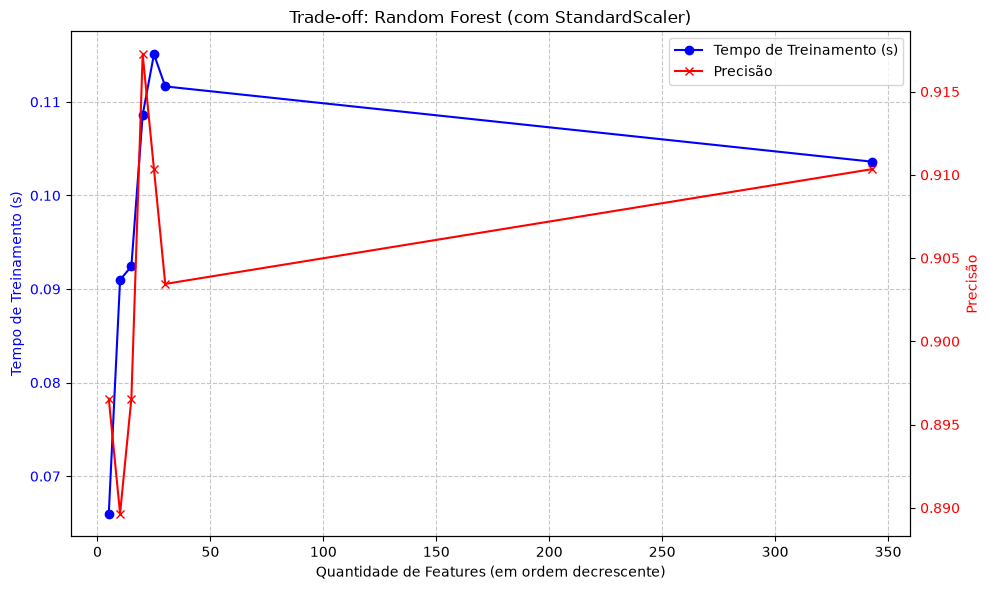

In [17]:
graficos.plot_tradeoff(rf_df, 'Trade-off: Random Forest (com StandardScaler)', 'blue', 'red')

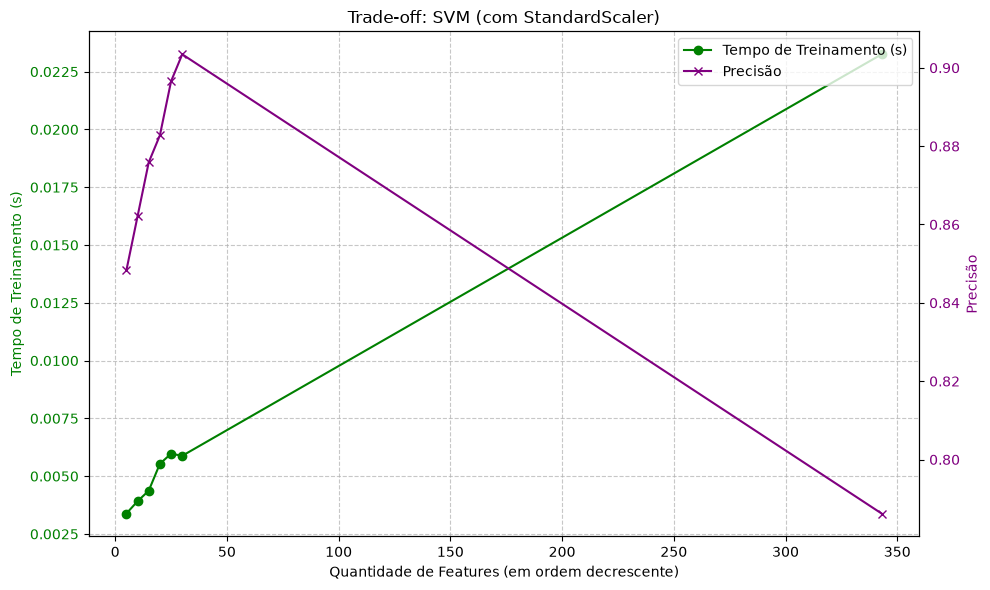

In [18]:
graficos.plot_tradeoff(svm_df, 'Trade-off: SVM (com StandardScaler)', 'green', 'purple')

---
#### Versão corrigida (Correções 1 e 2)

**Problemas na versão original (acima):**
- **Correção 1:** `feature_counts` pulava de 30 direto para ~343 — um vão de mais de 300 features sem nenhuma medição real, fazendo o gráfico "inventar" uma reta nesse trecho.
- **Correção 2:** cada `n_features` era treinado e medido **uma única vez** — o zigue-zague na precisão podia ser ruído de uma medição isolada, não uma tendência real.

**Correção aplicada:** `feature_counts` agora cobre o intervalo de forma mais densa (5 a 30 de 5 em 5, depois 50 a 300 de 50 em 50, mais o total), e cada ponto roda **3 vezes** (seeds 42, 43, 44), guardando a média e o desvio-padrão.

**Bônus:** este bloco já usa `svm_feature_importances_corrigido` (da Correção 3, ranking sem vazamento). O ranking do RF (`rf_scaled_feature_importances`) não precisou de correção — ele é nativo do modelo (`feature_importances_`), calculado só a partir do treino, sem tocar no teste.

Resultados salvos em `rf_df_corrigido` e `svm_df_corrigido` (variáveis novas — não sobrescrevem `rf_df`/`svm_df` originais).

In [19]:
# Correção 1: amostragem mais densa de n_features, cobrindo todo o intervalo
low_range = list(range(5, 31, 5))                                 # 5, 10, 15, 20, 25, 30
mid_range = list(range(50, min(total_features, 300) + 1, 50))     # 50, 100, 150, 200, 250, 300
contagens_corrigido = sorted(set([total_features] + mid_range + low_range), reverse=True)

# Correção 2: cada configuração roda 3 vezes (seeds 42, 43, 44) e guardamos a média
# Correção 3: o ranking do SVM vem da validação, não do teste
rf_df_corrigido = modelos.avaliar_tradeoff(rf_scaled_feature_importances['feature'].tolist(),
                                           X_treino_scaled, y_treino_balanceado, X_teste_scaled, y_teste,
                                           lambda seed: RandomForestClassifier(random_state=seed),
                                           contagens_corrigido, n_repeticoes=3)
svm_df_corrigido = modelos.avaliar_tradeoff(svm_feature_importances_corrigido['feature'].tolist(),
                                            X_treino_scaled, y_treino_balanceado, X_teste_scaled, y_teste,
                                            lambda seed: SVC(random_state=seed),
                                            contagens_corrigido, n_repeticoes=3)

---
#### Gráfico Random Forest — versão corrigida

Mesmos dados que alimentam o gráfico original resolveriam, mas agora usando `rf_df_corrigido`: eixo X por **posição** (categórico) em vez do valor numérico de `n_features` — isso evita a distorção visual do espaçamento desigual entre os pontos testados — e barras de erro (`errorbar`) mostrando o desvio-padrão das 3 execuções.

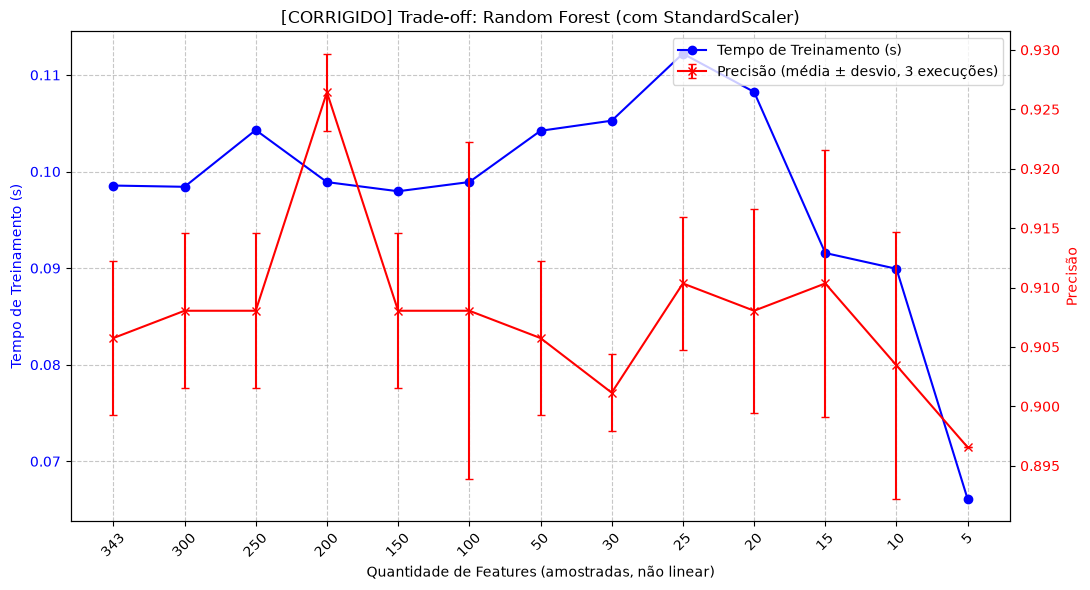

In [20]:
graficos.plot_tradeoff(rf_df_corrigido, '[CORRIGIDO] Trade-off: Random Forest (com StandardScaler)', 'blue', 'red', eixo_categorico=True)

---
#### Gráfico SVM — versão corrigida

Mesma correção do RF, agora usando `svm_df_corrigido` (que já carrega o ranking sem vazamento da Correção 3, mais a amostragem densa e as 3 repetições das Correções 1 e 2).

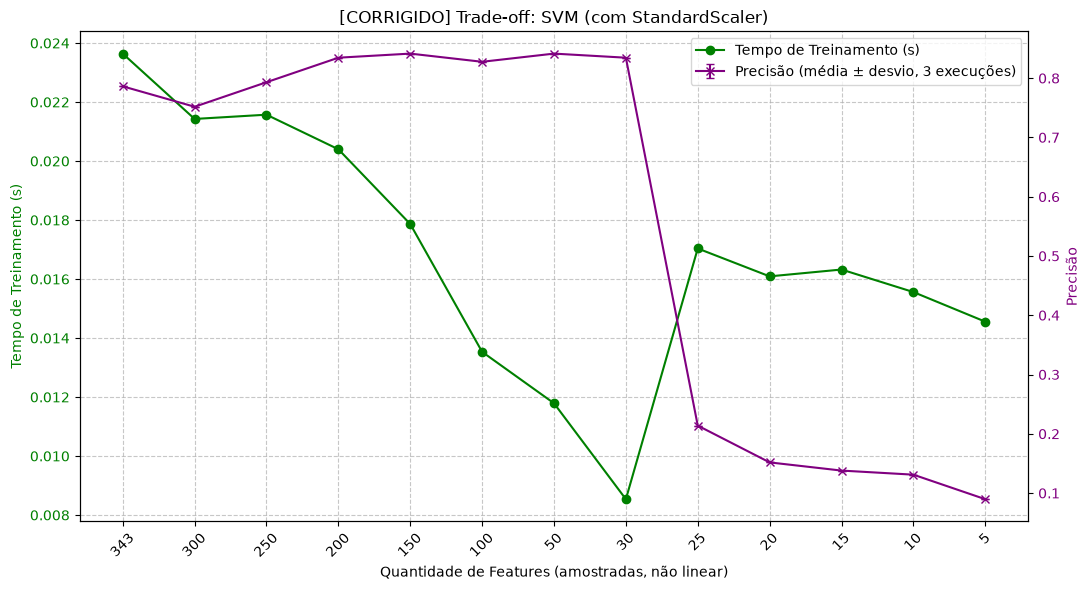

In [21]:
graficos.plot_tradeoff(svm_df_corrigido, '[CORRIGIDO] Trade-off: SVM (com StandardScaler)', 'green', 'purple', eixo_categorico=True)

## 7. Ajuste de Hiperparâmetros (SMOTE e dados originais)

### 7.1 Random Forest — SMOTE

Utilizando o `GridSearchCV`, buscamos a combinação de hiperparâmetros que maximiza o desempenho do Random Forest no conjunto completo de features (com StandardScaler), comparando o resultado com o modelo base (sem ajuste) treinado anteriormente.

> **Correção:** nos `GridSearchCV` com balanceamento, o SMOTE (ou SMOTENC/ENN) e o `StandardScaler` ficam dentro de um `Pipeline` do imblearn e recebem o treino **sem** balanceamento. Assim, em cada fold da validação cruzada eles são ajustados só na parte de treino, e nenhuma amostra sintética aparece na parte de validação. Os hiperparâmetros aparecem com o prefixo `modelo__`.

In [22]:
melhor_rf_smote, y_pred_rf_smote_otimizado, tempo_grid_rf_smote = modelos.rodar_grid(
    'rf_smote',
    Pipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', RandomForestClassifier(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_rf),
    X_treino_base, y_treino, X_teste_base, y_teste, 'Random Forest (SMOTE)')

### GridSearchCV — Random Forest (SMOTE) ###
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



Tempo total de busca: 53.4092 segundos
Melhores hiperparâmetros encontrados: {'modelo__max_depth': None, 'modelo__max_features': 'log2', 'modelo__min_samples_leaf': 2, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 100}
Melhor score (F1, média da validação cruzada): 0.6268

Relatório de Classificação Random Forest (SMOTE) (Otimizado):
              precision    recall  f1-score   support

           0       0.98      0.89      0.94       133
           1       0.42      0.83      0.56        12

    accuracy                           0.89       145
   macro avg       0.70      0.86      0.75       145
weighted avg       0.94      0.89      0.91       145

Matriz de Confusão Random Forest (SMOTE) (Otimizado):
 [[119  14]
 [  2  10]]
Acurácia Random Forest (SMOTE) (Otimizado): 0.8897


### 7.2 Random Forest — dados originais (sem balanceamento)

Ajuste dos hiperparâmetros no conjunto de treino com o desbalanceamento original.

> **Atenção:** este experimento usa `X_treino`, que ainda contém `redlistCategory` (vazamento proposital, identificado como tal na tabela consolidada).

In [23]:
melhor_rf_original, y_pred_rf_original_otimizado, tempo_grid_rf_original = modelos.rodar_grid(
    'rf_original',
    RandomForestClassifier(random_state=RANDOM_STATE),
    config.param_grid_rf,
    X_treino, y_treino, X_teste, y_teste, 'Random Forest (Dados Originais)')

### GridSearchCV — Random Forest (Dados Originais) ###
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



Tempo total de busca: 38.7412 segundos
Melhores hiperparâmetros encontrados: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Melhor score (F1, média da validação cruzada): 0.8674

Relatório de Classificação Random Forest (Dados Originais) (Otimizado):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       133
           1       1.00      0.92      0.96        12

    accuracy                           0.99       145
   macro avg       1.00      0.96      0.98       145
weighted avg       0.99      0.99      0.99       145

Matriz de Confusão Random Forest (Dados Originais) (Otimizado):
 [[133   0]
 [  1  11]]
Acurácia Random Forest (Dados Originais) (Otimizado): 0.9931


### 7.3 SVM — SMOTE (escalado)

In [24]:
melhor_svm_scaled, y_pred_svm_scaled_otimizado, tempo_grid_svm_scaled = modelos.rodar_grid(
    'svm_smote',
    Pipeline([
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', SVC(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_svm),
    X_treino_base, y_treino, X_teste_base, y_teste, 'SVM (SMOTE, Escalado)')

### GridSearchCV — SVM (SMOTE, Escalado) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 2.1034 segundos
Melhores hiperparâmetros encontrados: {'modelo__C': 100, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.4536

Relatório de Classificação SVM (SMOTE, Escalado) (Otimizado):
              precision    recall  f1-score   support

           0       0.97      0.91      0.94       133
           1       0.40      0.67      0.50        12

    accuracy                           0.89       145
   macro avg       0.68      0.79      0.72       145
weighted avg       0.92      0.89      0.90       145

Matriz de Confusão SVM (SMOTE, Escalado) (Otimizado):
 [[121  12]
 [  4   8]]
Acurácia SVM (SMOTE, Escalado) (Otimizado): 0.8897


### 7.4 SVM — dados originais (sem SMOTE, sem escalonamento)

Ajuste dos hiperparâmetros no conjunto de treino com o desbalanceamento original.

> **Atenção:** assim como na Seção 7.2, `X_treino` ainda contém `redlistCategory` (vazamento proposital).

In [25]:
melhor_svm_original, y_pred_svm_original_otimizado, tempo_grid_svm_original = modelos.rodar_grid(
    'svm_original',
    SVC(random_state=RANDOM_STATE),
    config.param_grid_svm,
    X_treino, y_treino, X_teste, y_teste, 'SVM (Dados Originais)')

### GridSearchCV — SVM (Dados Originais) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 0.8941 segundos
Melhores hiperparâmetros encontrados: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.2439

Relatório de Classificação SVM (Dados Originais) (Otimizado):
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       133
           1       0.00      0.00      0.00        12

    accuracy                           0.92       145
   macro avg       0.46      0.50      0.48       145
weighted avg       0.84      0.92      0.88       145

Matriz de Confusão SVM (Dados Originais) (Otimizado):
 [[133   0]
 [ 12   0]]
Acurácia SVM (Dados Originais) (Otimizado): 0.9172


/private/tmp/claude-501/-Users-kauacordeiro-Downloads-tcc/5f22f4b2-db2e-4480-8137-4277ee711877/scratchpad/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/private/tmp/claude-501/-Users-kauacordeiro-Downloads-tcc/5f22f4b2-db2e-4480-8137-4277ee711877/scratchpad/venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/private/tmp/claude-501/-Users-kauacordeiro-Downloads-tcc/5f22f4b2-db2e-4480-8137-4277ee711877/scratchpad/venv/lib/python3.12/site-packages/sklearn/metrics/_c

### 7.5 SVM — dados originais escalonados (sem SMOTE, sem `redlistCategory`)

In [26]:
melhor_svm_scaled_unbalanced, y_pred_svm_scaled_unbalanced_otimizado, tempo_grid_svm_scaled_unbalanced = modelos.rodar_grid(
    'svm_original_escalado',
    Pipeline([
        ('scaler', StandardScaler()),
        ('modelo', SVC(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_svm),
    X_treino_base, y_treino, X_teste_base, y_teste, 'SVM (Original Escalado)')

### GridSearchCV — SVM (Original Escalado) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 0.9525 segundos
Melhores hiperparâmetros encontrados: {'modelo__C': 10, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.4405

Relatório de Classificação SVM (Original Escalado) (Otimizado):
              precision    recall  f1-score   support

           0       0.96      0.92      0.94       133
           1       0.39      0.58      0.47        12

    accuracy                           0.89       145
   macro avg       0.67      0.75      0.70       145
weighted avg       0.91      0.89      0.90       145

Matriz de Confusão SVM (Original Escalado) (Otimizado):
 [[122  11]
 [  5   7]]
Acurácia SVM (Original Escalado) (Otimizado): 0.8897


## 8. SMOTENC

O SMOTENC é a variante do SMOTE para dados mistos: as colunas contínuas são interpoladas normalmente, mas as categóricas recebem o valor mais frequente entre os vizinhos, evitando valores "impossíveis" (ver Seção 8.5).

### 8.1 Identificação das colunas categóricas

In [27]:
# colunas_categoricas / indices_categoricos foram calculados na célula de dados:
# dummies (populationTrend, realm, familyName, genusName), systems e possiblyExtinct
print(f'Total de colunas categóricas identificadas: {len(indices_categoricos)}')
print(f'Total de colunas no X_treino_base: {X_treino_base.shape[1]}')

Total de colunas categóricas identificadas: 322
Total de colunas no X_treino_base: 343


### 8.2 Balanceamento com SMOTENC

In [28]:
smote_nc = SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)
X_treino_balanceado_nc, y_treino_balanceado_nc = smote_nc.fit_resample(X_treino_base, y_treino)

print("--- ANTES DO SMOTENC (Dados de Treino) ---")
print(y_treino.value_counts())
print("\n--- DEPOIS DO SMOTENC (Dados de Treino Balanceados) ---")
print(y_treino_balanceado_nc.value_counts())

--- ANTES DO SMOTENC (Dados de Treino) ---
label
0    528
1     48
Name: count, dtype: int64

--- DEPOIS DO SMOTENC (Dados de Treino Balanceados) ---
label
0    528
1    528
Name: count, dtype: int64


### 8.3 Modelos com configuração padrão (SMOTENC)

> **Correção:** o SVM agora é escalonado com `StandardScaler` também na configuração padrão (aqui e nas Seções 12.1 e 12.2), como nos SVMs otimizados. Antes, a comparação padrão × otimizado misturava o efeito do tuning com o do escalonamento.

In [29]:
rf_model_nc = RandomForestClassifier(random_state=RANDOM_STATE)
y_pred_rf_nc, tempo_treino_rf_nc = modelos.treinar_e_avaliar(
    rf_model_nc, X_treino_balanceado_nc, y_treino_balanceado_nc, X_teste_base, y_teste, 'Random Forest (SMOTENC)')

### Random Forest (SMOTENC) ###

Tempo de treinamento: 0.1004 segundos

Relatório de Classificação Random Forest (SMOTENC):
              precision    recall  f1-score   support

           0       0.96      0.95      0.95       133
           1       0.50      0.58      0.54        12

    accuracy                           0.92       145
   macro avg       0.73      0.77      0.75       145
weighted avg       0.92      0.92      0.92       145

Matriz de Confusão Random Forest (SMOTENC):
 [[126   7]
 [  5   7]]
Acurácia Random Forest (SMOTENC): 0.9172


In [30]:
# SVM (kernel RBF) é sensível à escala: escalonamos com StandardScaler dentro
# de um Pipeline, da mesma forma que nos SVMs otimizados
svm_model_nc = Pipeline([('scaler', StandardScaler()), ('modelo', SVC(random_state=RANDOM_STATE))])
y_pred_svm_nc, tempo_treino_svm_nc = modelos.treinar_e_avaliar(
    svm_model_nc, X_treino_balanceado_nc, y_treino_balanceado_nc, X_teste_base, y_teste, 'SVM (SMOTENC)')

### SVM (SMOTENC) ###

Tempo de treinamento: 0.0289 segundos

Relatório de Classificação SVM (SMOTENC):
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       133
           1       0.17      0.17      0.17        12

    accuracy                           0.86       145
   macro avg       0.55      0.55      0.55       145
weighted avg       0.86      0.86      0.86       145

Matriz de Confusão SVM (SMOTENC):
 [[123  10]
 [ 10   2]]
Acurácia SVM (SMOTENC): 0.8621


### 8.4 SMOTENC com ajuste de hiperparâmetros

In [31]:
melhor_rf_nc, y_pred_rf_nc_otimizado, tempo_grid_rf_nc = modelos.rodar_grid(
    'rf_smotenc',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', RandomForestClassifier(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_rf),
    X_treino_base, y_treino, X_teste_base, y_teste, 'Random Forest (SMOTENC)')

### GridSearchCV — Random Forest (SMOTENC) ###
Fitting 5 folds for each of 216 candidates, totalling 1080 fits



Tempo total de busca: 327.2438 segundos
Melhores hiperparâmetros encontrados: {'modelo__max_depth': 10, 'modelo__max_features': 'log2', 'modelo__min_samples_leaf': 1, 'modelo__min_samples_split': 2, 'modelo__n_estimators': 300}
Melhor score (F1, média da validação cruzada): 0.6170

Relatório de Classificação Random Forest (SMOTENC) (Otimizado):
              precision    recall  f1-score   support

           0       0.98      0.92      0.95       133
           1       0.50      0.83      0.62        12

    accuracy                           0.92       145
   macro avg       0.74      0.88      0.79       145
weighted avg       0.94      0.92      0.93       145

Matriz de Confusão Random Forest (SMOTENC) (Otimizado):
 [[123  10]
 [  2  10]]
Acurácia Random Forest (SMOTENC) (Otimizado): 0.9172


In [32]:
melhor_svm_nc, y_pred_svm_nc_otimizado, tempo_grid_svm_nc = modelos.rodar_grid(
    'svm_smotenc',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('modelo', SVC(random_state=RANDOM_STATE)),
    ]),
    modelos.grade_pipeline(config.param_grid_svm),
    X_treino_base, y_treino, X_teste_base, y_teste, 'SVM (SMOTENC, Escalado)')

### GridSearchCV — SVM (SMOTENC, Escalado) ###
Fitting 5 folds for each of 16 candidates, totalling 80 fits



Tempo total de busca: 31.1740 segundos
Melhores hiperparâmetros encontrados: {'modelo__C': 100, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}
Melhor score (F1, média da validação cruzada): 0.4655

Relatório de Classificação SVM (SMOTENC, Escalado) (Otimizado):
              precision    recall  f1-score   support

           0       0.96      0.90      0.93       133
           1       0.35      0.58      0.44        12

    accuracy                           0.88       145
   macro avg       0.66      0.74      0.68       145
weighted avg       0.91      0.88      0.89       145

Matriz de Confusão SVM (SMOTENC, Escalado) (Otimizado):
 [[120  13]
 [  5   7]]
Acurácia SVM (SMOTENC, Escalado) (Otimizado): 0.8759


### 8.5 Diagnóstico — contaminação categórica do SMOTE

Esta seção quantifica, de forma empírica, o problema conceitual do SMOTE tradicional discutido na Seção 5.3.2: como o algoritmo trata todas as colunas como contínuas durante a interpolação, colunas categóricas (binárias, one-hot e multi-label) recebem valores fracionários "impossíveis" nas amostras sintéticas geradas. Os resultados abaixo servem de justificativa quantitativa para a adoção do SMOTENC como alternativa.

In [33]:
print("### Diagnóstico: % de valores contínuos gerados pelo SMOTE em colunas categóricas ###")

# IMPORTANTE: o imblearn reaplica o dtype original de cada coluna ao montar o
# DataFrame de saída do SMOTE. Como nossas colunas categóricas são int64, os
# valores fracionários gerados pela interpolação são truncados de volta pra
# inteiro *antes* de chegarem até nós — escondendo o próprio problema que
# queremos medir. Para diagnosticar, rodamos o SMOTE novamente (mesma seed,
# só para fins de diagnóstico) sobre uma cópia com dtype float64 em todas as
# colunas, evitando esse truncamento silencioso.
X_treino_balanceado_diag, _ = SMOTE(random_state=RANDOM_STATE).fit_resample(X_treino_base.astype(float), y_treino)
X_sinteticas = X_treino_balanceado_diag.iloc[len(X_treino_base):]

print(f"Total de amostras originais: {len(X_treino_base)}")
print(f"Total de amostras sintéticas geradas: {len(X_sinteticas)}")

df_diagnostico, pct_medio_por_coluna, pct_linhas_invalidas = avaliacao.diagnostico_fracionario(
    X_sinteticas, colunas_categoricas)

print(f"\nColunas categóricas analisadas: {len(colunas_categoricas)}")
print(f"% médio de valores fracionários por coluna categórica: {pct_medio_por_coluna:.2f}%")
print(f"% de amostras sintéticas com pelo menos 1 valor fracionário em alguma coluna categórica: {pct_linhas_invalidas:.2f}%")
print("\nTop 10 colunas mais afetadas:")
print(df_diagnostico.head(10).to_string(index=False))

### Diagnóstico: % de valores contínuos gerados pelo SMOTE em colunas categóricas ###
Total de amostras originais: 576
Total de amostras sintéticas geradas: 480

Colunas categóricas analisadas: 322
% médio de valores fracionários por coluna categórica: 1.64%
% de amostras sintéticas com pelo menos 1 valor fracionário em alguma coluna categórica: 94.38%

Top 10 colunas mais afetadas:
                    coluna  pct_valores_fracionarios
         realm_Neotropical                 35.833333
      familyName_SCIURIDAE                 32.916667
        familyName_MURIDAE                 28.333333
         realm_Indomalayan                 27.083333
          realm_Palearctic                 26.250000
     familyName_CRICETIDAE                 21.458333
populationTrend_Decreasing                 20.833333
            realm_Nearctic                 19.583333
        realm_Australasian                 18.750000
   populationTrend_Unknown                 17.916667


In [34]:
print("### Diagnóstico: % de valores contínuos gerados pelo SMOTENC em colunas categóricas ###")

# Mesma cautela do diagnóstico anterior: forçamos float64 antes do fit_resample
# para garantir que nenhum truncamento de dtype esconda eventuais valores
# fracionários — mesmo sabendo que o SMOTENC, por design, deve preservar as
# categorias originais dos vizinhos (não interpola linearmente essas colunas).
smote_nc_diagnostico = SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)
X_treino_balanceado_nc_diag, _ = smote_nc_diagnostico.fit_resample(X_treino_base.astype(float), y_treino)
X_sinteticas_nc = X_treino_balanceado_nc_diag.iloc[len(X_treino_base):]

print(f"Total de amostras originais: {len(X_treino_base)}")
print(f"Total de amostras sintéticas geradas: {len(X_sinteticas_nc)}")

df_diagnostico_nc, pct_medio_por_coluna_nc, pct_linhas_invalidas_nc = avaliacao.diagnostico_fracionario(
    X_sinteticas_nc, colunas_categoricas)

print(f"\nColunas categóricas analisadas: {len(colunas_categoricas)}")
print(f"% médio de valores fracionários por coluna categórica: {pct_medio_por_coluna_nc:.2f}%")
print(f"% de amostras sintéticas com pelo menos 1 valor fracionário em alguma coluna categórica: {pct_linhas_invalidas_nc:.2f}%")

if df_diagnostico_nc['pct_valores_fracionarios'].sum() == 0:
    print("\nNenhum valor fracionário encontrado — confirma que o SMOTENC preserva")
    print("a integridade categórica por design, e não apenas por truncamento de dtype.")
else:
    print("\nTop 10 colunas mais afetadas:")
    print(df_diagnostico_nc.head(10).to_string(index=False))

### Diagnóstico: % de valores contínuos gerados pelo SMOTENC em colunas categóricas ###


Total de amostras originais: 576
Total de amostras sintéticas geradas: 480

Colunas categóricas analisadas: 322
% médio de valores fracionários por coluna categórica: 0.00%
% de amostras sintéticas com pelo menos 1 valor fracionário em alguma coluna categórica: 0.00%

Nenhum valor fracionário encontrado — confirma que o SMOTENC preserva
a integridade categórica por design, e não apenas por truncamento de dtype.


## 9. XGBoost (SMOTENC)

### 9.1 Configuração padrão

Terceiro modelo incluído na análise comparativa, escolhido por representar um paradigma distinto de ensemble (boosting sequencial, em vez do bagging do Random Forest ou da separação por hiperplano do SVM). Segue a mesma variante de balanceamento (SMOTENC) usada nos modelos otimizados anteriores, por ter se mostrado metodologicamente superior ao SMOTE tradicional (ver diagnóstico de contaminação categórica).

In [35]:
# eval_metric='logloss' evita o warning de deprecação do XGBoost recente,
# que passou a exigir a métrica de avaliação explícita no construtor
xgb_model_nc = XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
y_pred_xgb_nc, tempo_treino_xgb_nc = modelos.treinar_e_avaliar(
    xgb_model_nc, X_treino_balanceado_nc, y_treino_balanceado_nc, X_teste_base, y_teste, 'XGBoost (SMOTENC)')

### XGBoost (SMOTENC) ###



Tempo de treinamento: 0.2068 segundos

Relatório de Classificação XGBoost (SMOTENC):
              precision    recall  f1-score   support

           0       0.96      0.93      0.95       133
           1       0.44      0.58      0.50        12

    accuracy                           0.90       145
   macro avg       0.70      0.76      0.72       145
weighted avg       0.92      0.90      0.91       145

Matriz de Confusão XGBoost (SMOTENC):
 [[124   9]
 [  5   7]]
Acurácia XGBoost (SMOTENC): 0.9034


### 9.2 Ajuste de hiperparâmetros

In [36]:
melhor_xgb_nc, y_pred_xgb_nc_otimizado, tempo_grid_xgb_nc = modelos.rodar_grid(
    'xgb_smotenc',
    Pipeline([
        ('smotenc', SMOTENC(categorical_features=indices_categoricos, random_state=RANDOM_STATE)),
        ('modelo', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')),
    ]),
    modelos.grade_pipeline(config.param_grid_xgb),
    X_treino_base, y_treino, X_teste_base, y_teste, 'XGBoost (SMOTENC)')

### GridSearchCV — XGBoost (SMOTENC) ###
Fitting 5 folds for each of 108 candidates, totalling 540 fits



Tempo total de busca: 195.5185 segundos
Melhores hiperparâmetros encontrados: {'modelo__colsample_bytree': 1.0, 'modelo__learning_rate': 0.2, 'modelo__max_depth': 3, 'modelo__n_estimators': 100, 'modelo__subsample': 0.8}
Melhor score (F1, média da validação cruzada): 0.5628

Relatório de Classificação XGBoost (SMOTENC) (Otimizado):
              precision    recall  f1-score   support

           0       0.98      0.95      0.96       133
           1       0.56      0.75      0.64        12

    accuracy                           0.93       145
   macro avg       0.77      0.85      0.80       145
weighted avg       0.94      0.93      0.94       145

Matriz de Confusão XGBoost (SMOTENC) (Otimizado):
 [[126   7]
 [  3   9]]
Acurácia XGBoost (SMOTENC) (Otimizado): 0.9310


## 10. Tabela Consolidada de Resultados

Reúne, para fins de comparação direta, as métricas de todos os experimentos válidos de Random Forest, SVM e XGBoost. Os experimentos que ainda contêm a feature `redlistCategory` aparecem apenas como referência, identificados com "leakage proposital" na coluna `balanceamento`, pois não representam uma avaliação válida do poder preditivo real dos modelos.

In [37]:
registrar = avaliacao.registrar_resultado

# --- Random Forest ---
registrar(resultados_experimentos, 'Random Forest', 'SMOTE', tuning=False,
          y_true=y_teste, y_pred=y_pred_rf, tempo_treino=tempo_treino_rf)
registrar(resultados_experimentos, 'Random Forest', 'SMOTE (StandardScaler)', tuning=False,
          y_true=y_teste, y_pred=y_pred_rf_scaled, tempo_treino=tempo_treino_rf_scaled)
registrar(resultados_experimentos, 'Random Forest', 'SMOTE', tuning=True,
          y_true=y_teste, y_pred=y_pred_rf_smote_otimizado, tempo_treino=tempo_grid_rf_smote)
registrar(resultados_experimentos, 'Random Forest', 'Original — COM redlistCategory (leakage proposital)', tuning=True,
          y_true=y_teste, y_pred=y_pred_rf_original_otimizado, tempo_treino=tempo_grid_rf_original)
registrar(resultados_experimentos, 'Random Forest', 'SMOTENC', tuning=False,
          y_true=y_teste, y_pred=y_pred_rf_nc, tempo_treino=tempo_treino_rf_nc)
registrar(resultados_experimentos, 'Random Forest', 'SMOTENC', tuning=True,
          y_true=y_teste, y_pred=y_pred_rf_nc_otimizado, tempo_treino=tempo_grid_rf_nc)

# --- SVM ---
registrar(resultados_experimentos, 'SVM', 'SMOTE (StandardScaler)', tuning=False,
          y_true=y_teste, y_pred=y_pred_svm, tempo_treino=tempo_treino_svm)
registrar(resultados_experimentos, 'SVM', 'SMOTE (StandardScaler)', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_scaled_otimizado, tempo_treino=tempo_grid_svm_scaled)
registrar(resultados_experimentos, 'SVM', 'Original — COM redlistCategory (leakage proposital)', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_original_otimizado, tempo_treino=tempo_grid_svm_original)
registrar(resultados_experimentos, 'SVM', 'Original (sem balanceamento, escalado)', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_scaled_unbalanced_otimizado, tempo_treino=tempo_grid_svm_scaled_unbalanced)
registrar(resultados_experimentos, 'SVM', 'SMOTENC', tuning=False,
          y_true=y_teste, y_pred=y_pred_svm_nc, tempo_treino=tempo_treino_svm_nc)
registrar(resultados_experimentos, 'SVM', 'SMOTENC', tuning=True,
          y_true=y_teste, y_pred=y_pred_svm_nc_otimizado, tempo_treino=tempo_grid_svm_nc)

# --- XGBoost ---
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC', tuning=False,
          y_true=y_teste, y_pred=y_pred_xgb_nc, tempo_treino=tempo_treino_xgb_nc)
registrar(resultados_experimentos, 'XGBoost', 'SMOTENC', tuning=True,
          y_true=y_teste, y_pred=y_pred_xgb_nc_otimizado, tempo_treino=tempo_grid_xgb_nc)

# Salva a lista (na ordem de registro) para o notebook 03
pd.DataFrame(resultados_experimentos).to_csv(config.RESULTADOS_MODELAGEM_PATH, index=False)

df_resultados = avaliacao.tabela_resultados(resultados_experimentos)
print(f"Total de experimentos registrados: {len(df_resultados)}\n")
df_resultados.round(4)

Total de experimentos registrados: 14



,modelo,balanceamento,tuning,acuracia,precisao,recall,f1,tempo_treino_s
0,Random Forest,Original — COM redlistCategory (leakage proposital),Sim,0.9931,1.0000,0.9167,0.9565,38.7412
1,XGBoost,SMOTENC,Sim,0.9310,0.5625,0.7500,0.6429,195.5185
2,Random Forest,SMOTENC,Sim,0.9172,0.5000,0.8333,0.6250,327.2438
3,Random Forest,SMOTE,Sim,0.8897,0.4167,0.8333,0.5556,53.4092
4,Random Forest,SMOTENC,Não,0.9172,0.5000,0.5833,0.5385,0.1004
5,Random Forest,SMOTE,Não,0.9103,0.4667,0.5833,0.5185,0.1046
6,Random Forest,SMOTE (StandardScaler),Não,0.9103,0.4667,0.5833,0.5185,0.1085
7,SVM,SMOTE (StandardScaler),Sim,0.8897,0.4000,0.6667,0.5000,2.1034
8,XGBoost,SMOTENC,Não,0.9034,0.4375,0.5833,0.5000,0.2068
9,SVM,"Original (sem balanceamento, escalado)",Sim,0.8897,0.3889,0.5833,0.4667,0.9525


### 10.1 Exportação dos datasets

Os conjuntos de treino e teste são salvos em `data/final_data/`.

In [38]:
# Conjunto de treino balanceado por SMOTE (com redlistCategory, usado só na Seção 6.1)
dados.exportar_dataset(X_treino_balanceado, y_treino_balanceado, 'rodentia_treino_smote.csv')

# Conjunto de treino balanceado por SMOTENC (sem redlistCategory)
dados.exportar_dataset(X_treino_balanceado_nc, y_treino_balanceado_nc, 'rodentia_treino_smotenc.csv')

# Conjunto de treino balanceado por SMOTE sem redlistCategory e normalizado (StandardScaler), usado no SVM da Seção 6.5
dados.exportar_dataset(X_treino_scaled, y_treino_balanceado, 'rodentia_treino_normalizado_svm.csv')

# Conjunto de teste (holdout), sem redlistCategory — usado na avaliação da maioria dos modelos
dados.exportar_dataset(X_teste_base, y_teste, 'rodentia_teste_holdout.csv')

Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_treino_smote.csv  (shape: (1056, 345))


Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_treino_smotenc.csv  (shape: (1056, 344))


Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_treino_normalizado_svm.csv  (shape: (1056, 344))
Exportado: /Users/kauacordeiro/Downloads/tcc/data/final_data/rodentia_teste_holdout.csv  (shape: (145, 344))
